<a href="https://colab.research.google.com/github/al05076977-prog/Avanze-proyecto2/blob/main/Avance_proyecto2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import nltk
import unicodedata

from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from nltk.tokenize import word_tokenize

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report)

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
for recurso in ["punkt", "punkt_tab", "stopwords"]:
    nltk.download(recurso, quiet=True)

stemmer = SnowballStemmer("spanish")
STOP = set(stopwords.words("spanish"))

In [3]:
datos = {
    "texto": [

        # SALUDO
        "Hola",
        "Hola, buenos días",
        "Buenos días",
        "Buenas tardes",
        "Buenas noches",
        "Hola, ¿cómo estás?",
        "Qué tal",
        "Hola, necesito información",
        "Saludos",
        "Hola, tengo una duda",
        "Buen día",
        "Hola, quisiera hacer una consulta",
        "Qué onda",
        "Hola, necesito orientación",
        "Hola, ¿me puedes ayudar?",
        "Buenas",
        "Qué tal, tengo una pregunta",
        "Hola, quisiera preguntarte algo",
        "Saludos, necesito ayuda",
        "Hola, quiero hacer una consulta",

        # DESPEDIDA
        "Adiós",
        "Hasta luego",
        "Muchas gracias",
        "Gracias por la ayuda",
        "Nos vemos",
        "Hasta pronto",
        "Eso es todo, gracias",
        "Gracias por la información",
        "Me quedó claro, gracias",
        "Ya no tengo más preguntas",
        "Eso sería todo",
        "Gracias, adiós",
        "Nos vemos después",
        "Hasta la próxima",
        "Muchas gracias por explicarlo",
        "Listo, gracias",
        "Con eso termino",
        "Eso era todo lo que necesitaba",
        "Perfecto, hasta luego",
        "Gracias, nos vemos",

        # AYUDA
        "¿Qué puedes hacer?",
        "¿En qué me puedes ayudar?",
        "¿Qué temas conoces?",
        "Necesito ayuda",
        "¿Qué información puedes darme?",
        "¿Sobre qué temas puedo preguntarte?",
        "¿Qué tipo de preguntas respondes?",
        "¿Cómo funciona este asistente?",
        "Quiero saber qué puedes hacer",
        "Muéstrame las opciones",
        "¿Qué temas financieros manejas?",
        "¿Para qué sirve este asistente?",
        "Necesito orientación",
        "¿Qué tipo de información tienes?",
        "Dime en qué puedes ayudarme",
        "¿Qué cosas puedo preguntarte?",
        "Quiero conocer tus funciones",
        "¿Qué servicios proporciona el asistente?",
        "Explícame cómo puedes ayudarme",
        "¿Qué opciones tengo?",

        # AHORRO
        "¿Cómo puedo empezar a ahorrar?",
        "Quiero aprender a ahorrar dinero",
        "¿Cuánto debería ahorrar cada mes?",
        "Quiero guardar parte de mi sueldo",
        "¿Qué porcentaje de mis ingresos debería guardar?",
        "Me gustaría juntar dinero para el futuro",
        "¿Cómo puedo crear el hábito de ahorrar?",
        "No sé cómo empezar a guardar dinero",
        "¿Qué estrategia puedo utilizar para ahorrar?",
        "Quiero reducir mis gastos para guardar más dinero",
        "¿Cómo puedo organizarme para tener ahorros?",
        "Quiero tener dinero guardado para el futuro",
        "¿Es importante ahorrar todos los meses?",
        "¿Cuál es una buena forma de comenzar a guardar dinero?",
        "Me cuesta trabajo separar dinero de mi sueldo",
        "¿Cómo puedo gastar menos y guardar más?",
        "Quisiera formar un ahorro poco a poco",
        "¿Qué cantidad de mis ingresos conviene guardar?",
        "Quiero mejorar mis hábitos de ahorro",
        "¿Qué consejos existen para guardar dinero?",

        # FONDO DE EMERGENCIA
        "¿Qué es un fondo de emergencia?",
        "¿Cuánto dinero debería tener para una emergencia?",
        "Quiero prepararme para gastos imprevistos",
        "¿Cómo puedo crear un fondo para emergencias?",
        "¿Cuántos meses de gastos debería tener guardados?",
        "Necesito dinero disponible para cualquier imprevisto",
        "¿Dónde debería guardar mi dinero de emergencia?",
        "Quiero estar preparado si pierdo mi empleo",
        "¿Para qué sirve un fondo de emergencia?",
        "¿Cómo puedo protegerme ante un gasto inesperado?",
        "¿Es necesario tener dinero reservado para emergencias?",
        "Quiero crear un colchón financiero",
        "¿Cuánto debo guardar para gastos inesperados?",
        "¿Cómo empiezo a construir un fondo de emergencia?",
        "Necesito estar preparado para una situación inesperada",
        "¿Qué gastos debería cubrir un fondo de emergencia?",
        "Quiero tener una reserva para cualquier problema",
        "¿En cuánto tiempo puedo formar un fondo de emergencia?",
        "¿Puedo utilizar mis ahorros como fondo de emergencia?",
        "¿Qué cantidad necesito guardar para estar preparado?",

        # PRESUPUESTO
        "¿Cómo puedo hacer un presupuesto?",
        "Quiero organizar mejor mis ingresos y gastos",
        "¿Cómo puedo controlar mis gastos del mes?",
        "No sé en qué se me va el dinero",
        "¿Cómo puedo administrar mejor mi sueldo?",
        "Quiero hacer un plan para mis gastos mensuales",
        "¿Qué debo incluir en un presupuesto?",
        "¿Cómo puedo distribuir mis ingresos cada mes?",
        "Necesito organizar mis gastos personales",
        "¿Cuál es la mejor forma de controlar mis gastos?",
        "Quiero saber cuánto puedo gastar al mes",
        "¿Cómo registro mis ingresos y mis gastos?",
        "¿Para qué sirve hacer un presupuesto?",
        "¿Cómo puedo planear mis gastos?",
        "Quiero tener mayor control de mi dinero",
        "¿Cómo puedo organizar mis finanzas del mes?",
        "¿Debo registrar todos mis gastos?",
        "¿Cómo puedo saber cuánto dinero me queda disponible?",
        "Quiero establecer límites para mis gastos",
        "¿Cómo puedo dividir mi sueldo entre mis diferentes gastos?",

        # INFLACION
        "¿Qué es la inflación?",
        "¿Por qué suben los precios?",
        "¿Cómo afecta la inflación a mi dinero?",
        "¿Qué significa que haya inflación?",
        "¿Por qué mi dinero alcanza para menos cosas?",
        "¿Cómo afecta el aumento de precios a mis ahorros?",
        "Quiero entender cómo funciona la inflación",
        "¿Qué provoca que los precios aumenten?",
        "¿Qué relación tiene la inflación con el poder adquisitivo?",
        "¿Cómo puedo proteger mi dinero de la inflación?",
        "¿Por qué las cosas cuestan más que antes?",
        "¿Qué es el INPC?",
        "¿Cómo se mide el aumento general de los precios?",
        "¿La inflación hace que mi dinero pierda valor?",
        "¿Cómo afecta la inflación a mis gastos mensuales?",
        "Quiero saber por qué aumenta el costo de vida",
        "¿Qué pasa con mis ahorros cuando hay inflación?",
        "¿Cómo influye la inflación en la economía familiar?",
        "¿Por qué pierdo poder adquisitivo?",
        "Explícame de forma sencilla qué es la inflación",

        # TARJETA DE CREDITO
        "¿Cómo funciona una tarjeta de crédito?",
        "¿Qué pasa si pago solamente el mínimo?",
        "¿Cómo debo utilizar mi tarjeta de crédito?",
        "¿Qué ocurre si no pago mi tarjeta a tiempo?",
        "¿Cómo funcionan los intereses de una tarjeta?",
        "¿Qué significa el límite de crédito?",
        "Quiero aprender a utilizar correctamente mi tarjeta",
        "¿Debo pagar toda mi tarjeta cada mes?",
        "¿Qué pasa si me atraso con el pago?",
        "¿Cómo puedo evitar pagar intereses con mi tarjeta?",
        "¿Qué significa la fecha de corte?",
        "¿Qué es la fecha límite de pago?",
        "¿Es malo utilizar una tarjeta de crédito?",
        "¿Cómo puedo controlar mis compras con tarjeta?",
        "¿Qué debo revisar antes de contratar una tarjeta?",
        "¿Cómo funcionan las compras a crédito?",
        "¿Por qué aumenta la deuda de mi tarjeta?",
        "¿Es recomendable pagar más del mínimo?",
        "¿Qué debo hacer para manejar correctamente mi crédito?",
        "Quiero entender cómo funcionan las tarjetas bancarias",

        # CAT
        "¿Qué es el CAT?",
        "¿Qué significa Costo Anual Total?",
        "¿Para qué sirve el CAT de un crédito?",
        "¿Cómo puedo comparar créditos usando el CAT?",
        "¿Qué incluye el Costo Anual Total?",
        "¿Es mejor un crédito con CAT bajo?",
        "Quiero entender el CAT de mi préstamo",
        "¿Cómo influye el CAT en el costo de un crédito?",
        "¿Qué diferencia existe entre tasa de interés y CAT?",
        "¿Por qué debo revisar el CAT antes de pedir un préstamo?",
        "¿El CAT incluye las comisiones?",
        "¿Cómo sé qué crédito es más barato?",
        "¿Qué me dice el CAT de una tarjeta?",
        "¿Debo elegir el préstamo que tenga menor CAT?",
        "¿Dónde puedo consultar el CAT de un crédito?",
        "Quiero comparar el costo de dos préstamos",
        "¿Cómo se usa el CAT para comparar tarjetas?",
        "¿Qué gastos considera el Costo Anual Total?",
        "¿El CAT representa el costo real de un préstamo?",
        "Explícame de manera sencilla qué significa CAT",

        # CETES
        "¿Qué son los CETES?",
        "¿Cómo puedo invertir en CETES?",
        "¿Es seguro invertir en CETES?",
        "¿Qué rendimiento ofrecen los CETES?",
        "Quiero comenzar a invertir en CETES",
        "¿Cómo funcionan los CETES?",
        "¿Dónde puedo comprar CETES?",
        "¿Qué necesito para invertir en CETES?",
        "¿Los CETES son una inversión del gobierno?",
        "¿Cuánto dinero necesito para empezar a invertir?",
        "¿Qué pasa con mi dinero cuando compro CETES?",
        "¿Cuándo recibo el rendimiento de los CETES?",
        "¿Puedo invertir mis ahorros en CETES?",
        "¿Qué ventajas tiene invertir en CETES?",
        "Quiero entender cómo funcionan las inversiones en CETES",
        "¿Los CETES tienen riesgo?",
        "¿Qué significa el vencimiento de un CETE?",
        "¿Cómo puedo comenzar a invertir mi dinero?",
        "¿CETES es una opción para principiantes?",
        "Explícame de forma sencilla qué son los CETES",

        # AFORE
        "¿Qué es una Afore?",
        "¿Para qué sirve mi Afore?",
        "¿Cómo funciona el ahorro para el retiro?",
        "¿Cómo puedo saber cuánto dinero tengo en mi Afore?",
        "¿Qué son las aportaciones voluntarias?",
        "Quiero ahorrar más dinero para mi retiro",
        "¿Cómo funciona una cuenta individual de retiro?",
        "¿Quién administra mi ahorro para el retiro?",
        "¿Puedo hacer aportaciones adicionales a mi Afore?",
        "¿Cómo puedo mejorar mi ahorro para la jubilación?",
        "¿Qué pasa con el dinero de mi Afore?",
        "¿Dónde puedo consultar mi ahorro para el retiro?",
        "¿Qué institución regula las Afores?",
        "¿Es importante ahorrar adicionalmente para el retiro?",
        "Quiero prepararme financieramente para mi jubilación",
        "¿Cómo puedo revisar el saldo de mi Afore?",
        "¿Qué beneficios tienen las aportaciones voluntarias?",
        "¿Cómo puedo planear financieramente mi retiro?",
        "¿Mi Afore genera rendimientos?",
        "Explícame de forma sencilla cómo funciona una Afore",

        # DEUDAS
        "¿Cómo puedo salir de mis deudas?",
        "Tengo muchas deudas y no sé qué hacer",
        "¿Qué deuda debería pagar primero?",
        "¿Cómo puedo organizar el pago de mis deudas?",
        "Quiero dejar de estar endeudado",
        "¿Qué es el método bola de nieve?",
        "¿Qué es el método avalancha?",
        "No puedo pagar todos mis préstamos",
        "¿Cómo puedo reducir mis deudas?",
        "¿Debo pagar primero la deuda con mayor interés?",
        "¿Cómo puedo evitar endeudarme más?",
        "Necesito un plan para pagar lo que debo",
        "¿Qué hago si ya no puedo pagar un crédito?",
        "¿Es posible reestructurar una deuda?",
        "¿Cómo puedo controlar mis préstamos?",
        "Tengo varios créditos y quiero liquidarlos",
        "¿Qué estrategia puedo seguir para pagar mis deudas?",
        "Mis deudas están creciendo demasiado",
        "¿Cómo puedo recuperar el control de mis deudas?",
        "Quiero aprender a manejar mejor lo que debo",

        # FRAUDE
        "¿Cómo puedo evitar un fraude?",
        "¿Cómo puedo protegerme de una estafa?",
        "¿Qué es el phishing?",
        "¿Cómo puedo saber si un mensaje del banco es falso?",
        "¿Qué hago si alguien intenta robar mis datos bancarios?",
        "¿Cómo identifico una página bancaria falsa?",
        "¿Qué debo hacer si recibo una llamada sospechosa?",
        "¿Cómo puedo proteger mis contraseñas bancarias?",
        "¿Es seguro compartir mi NIP por teléfono?",
        "¿Qué hago si veo un cargo que no reconozco?",
        "¿Cómo puedo saber si una inversión es una estafa?",
        "¿Qué datos bancarios nunca debo compartir?",
        "¿Cómo puedo prevenir un fraude financiero?",
        "Recibí un mensaje extraño pidiendo mis datos",
        "¿Qué debo hacer ante un correo sospechoso?",
        "Creo que intentaron engañarme con una transferencia",
        "¿Cómo puedo reconocer un intento de phishing?",
        "¿Qué hago si robaron los datos de mi tarjeta?",
        "¿Cómo puedo proteger mis cuentas bancarias?",
        "¿Cómo puedo prevenirme contra un fraude?"
    ],

    "intencion": (
        ["saludo"] * 20 +
        ["despedida"] * 20 +
        ["ayuda"] * 20 +
        ["ahorro"] * 20 +
        ["fondo_emergencia"] * 20 +
        ["presupuesto"] * 20 +
        ["inflacion"] * 20 +
        ["tarjeta_credito"] * 20 +
        ["cat"] * 20 +
        ["cetes"] * 20 +
        ["afore"] * 20 +
        ["deudas"] * 20 +
        ["fraude"] * 20)}

df = pd.DataFrame(datos)

df.head()

,texto,intencion
0,Hola,saludo
1,"Hola, buenos días",saludo
2,Buenos días,saludo
3,Buenas tardes,saludo
4,Buenas noches,saludo


In [4]:
respuestas_combinadas = {
    ("ahorro", "alcancia"):
        "La imagen muestra una alcancía, un objeto relacionado con el ahorro. "
        "Puedes utilizarla para separar pequeñas cantidades de dinero y comenzar "
        "a desarrollar el hábito de ahorrar.",

    ("ahorro", "billete"):
        "La imagen muestra un billete. Una opción para comenzar a ahorrar es "
        "separar una parte del dinero que recibes antes de realizar tus gastos.",

    ("ahorro", "moneda"):
        "La imagen muestra una moneda. Aunque parezca una cantidad pequeña, "
        "guardar monedas de manera constante puede ayudarte a formar un hábito de ahorro.",

    ("presupuesto", "reportes_financieros"):
        "La imagen parece corresponder a un reporte financiero. Este tipo de "
        "documento puede ayudarte a registrar y comparar tus ingresos y gastos "
        "para preparar un presupuesto.",

    ("tarjeta_credito", "tarjeta_credito"):
        "La imagen muestra una tarjeta de crédito. Es importante revisar la fecha "
        "de corte, la fecha límite de pago y procurar pagar más del mínimo para "
        "evitar que la deuda aumente.",

    ("cat", "tarjeta_credito"):
        "La imagen muestra una tarjeta de crédito. Al comparar este tipo de productos, "
        "el CAT permite tener una referencia del costo total del financiamiento.",

    ("deudas", "tarjeta_credito"):
        "La imagen muestra una tarjeta de crédito. Si tienes una deuda, conviene "
        "revisar el saldo, la tasa de interés y el pago necesario para reducirla.",

    ("fraude", "tarjeta_credito"):
        "La imagen muestra una tarjeta bancaria. Para reducir el riesgo de fraude, "
        "evita compartir el NIP, el CVV o los códigos recibidos por mensaje.",

    ("cetes", "banco"):
        "La imagen parece mostrar un banco. Sin embargo, los CETES pueden adquirirse "
        "directamente mediante CETESdirecto, sin necesidad de acudir a una sucursal.",

    ("fondo_emergencia", "alcancia"):
        "La imagen muestra una alcancía. Puede representar el inicio de un fondo "
        "de emergencia, aunque el dinero debería guardarse posteriormente en un "
        "lugar seguro y accesible."}

In [5]:
print("Número total de registros:", len(df))
print("Número de intenciones:", df["intencion"].nunique())

Número total de registros: 260
Número de intenciones: 13


In [6]:
df["intencion"].value_counts()

,count
intencion,
saludo,20
despedida,20
ayuda,20
ahorro,20
fondo_emergencia,20
presupuesto,20
inflacion,20
tarjeta_credito,20
cat,20


In [7]:
def quitar_acentos(texto):
    nfd = unicodedata.normalize("NFD", texto)

    texto_sin_acentos = "".join(
        caracter
        for caracter in nfd
        if unicodedata.category(caracter) != "Mn")

    return texto_sin_acentos

In [8]:
def preprocesar_texto(texto):

    # Convertir a minusculas
    texto = texto.lower()

    # Eliminar de acentos
    texto = quitar_acentos(texto)

    # Tokenización
    tokens = word_tokenize(texto, language="spanish")

    # Conservar solamente palabras
    tokens = [
        palabra
        for palabra in tokens
        if palabra.isalpha()]

    # Eliminacion de stopwords
    tokens = [
        palabra
        for palabra in tokens
        if palabra not in STOP]

    # Stemming
    tokens = [
        stemmer.stem(palabra)
        for palabra in tokens]

    # Volver a unir las palabras
    texto_procesado = " ".join(tokens)

    return texto_procesado

In [9]:
def mostrar_preprocesamiento(texto):

    print("Texto original:")
    print(texto)

    # Normalización
    normalizado = quitar_acentos(texto.lower())

    print("\n1. Normalización:")
    print(normalizado)

    # Tokenización
    tokens = word_tokenize(normalizado, language="spanish")

    print("\n2. Tokenización:")
    print(tokens)

    # Solamente palabras
    tokens_palabras = [
        palabra
        for palabra in tokens
        if palabra.isalpha()]

    # Eliminación de stopwords
    sin_stopwords = [
        palabra
        for palabra in tokens_palabras
        if palabra not in STOP]

    print("\n3. Eliminación de stopwords:")
    print(sin_stopwords)

    # Stemming
    palabras_stem = [
        stemmer.stem(palabra)
        for palabra in sin_stopwords]


In [10]:
df["texto_procesado"] = df["texto"].apply(preprocesar_texto)

df.head(10)

,texto,intencion,texto_procesado
0,Hola,saludo,hol
1,"Hola, buenos días",saludo,hol buen dias
2,Buenos días,saludo,buen dias
3,Buenas tardes,saludo,buen tard
4,Buenas noches,saludo,buen noch
5,"Hola, ¿cómo estás?",saludo,hol
6,Qué tal,saludo,tal
7,"Hola, necesito información",saludo,hol necesit inform
8,Saludos,saludo,salud
9,"Hola, tengo una duda",saludo,hol dud


In [11]:
X = df["texto_procesado"]
y = df["intencion"]

print("Número de textos:", len(X))
print("Número de etiquetas:", len(y))

Número de textos: 260
Número de etiquetas: 260


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y)

print("Datos de entrenamiento:", len(X_train))
print("Datos de prueba:", len(X_test))

Datos de entrenamiento: 208
Datos de prueba: 52


In [13]:
tfidf = TfidfVectorizer()

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

In [14]:
print(X_train_tfidf.shape)
print(X_test_tfidf.shape)

(208, 237)
(52, 237)


In [15]:
indice = 0

texto_ejemplo = X_train.iloc[indice]
vector = X_train_tfidf[indice]

print("Texto procesado:")
print(texto_ejemplo)

print("\nTérminos con peso TF-IDF:")

for posicion in vector.nonzero()[1]:
    termino = tfidf.get_feature_names_out()[posicion]
    peso = vector[0, posicion]

    print(f"{termino}: {peso:.4f}")


Texto procesado:
termin

Términos con peso TF-IDF:
termin: 1.0000


In [16]:
modelo_svm = SVC(
    kernel="linear",
    C=1.0,
    random_state=42)

modelo_svm.fit(X_train_tfidf, y_train)

print("Modelo SVM entrenado correctamente.")

Modelo SVM entrenado correctamente.


In [17]:
y_pred = modelo_svm.predict(X_test_tfidf)

resultados = pd.DataFrame({
    "texto_procesado": X_test.values,
    "intencion_real": y_test.values,
    "intencion_predicha": y_pred})

resultados.head(10)

,texto_procesado,intencion_real,intencion_predicha
0,deb hac si recib llam sospech,fraude,tarjeta_credito
1,quier ten diner guard futur,ahorro,ahorro
2,quier entend funcion inversion cet,cetes,cetes
3,tip pregunt respond,ayuda,despedida
4,necesit ayud,ayuda,saludo
5,signif fech cort,tarjeta_credito,cat
6,buen noch,saludo,saludo
7,pued sab si inversion estaf,fraude,fraude
8,mejor form control gast,presupuesto,presupuesto
9,sirv cat credit,cat,cat


In [18]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision (macro): {precision:.4f}")
print(f"Recall (macro):    {recall:.4f}")
print(f"F1-score (macro):  {f1:.4f}")

Accuracy:  0.7500
Precision (macro): 0.7923
Recall (macro):    0.7500
F1-score (macro):  0.7281


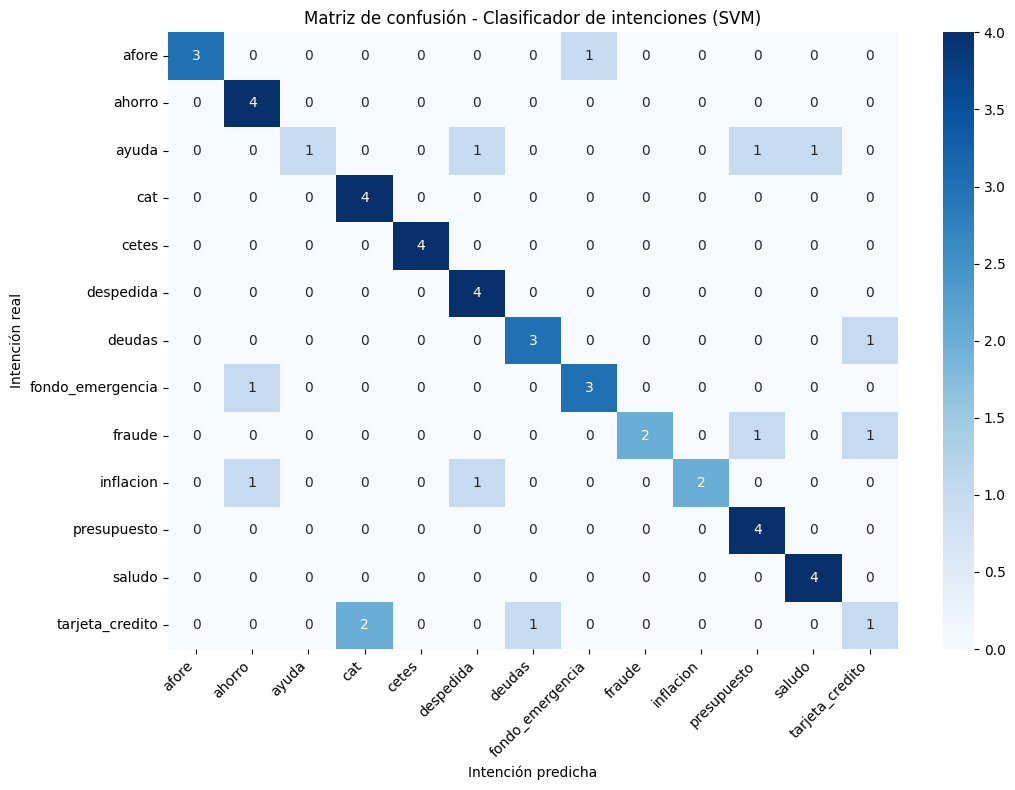

In [19]:
etiquetas = sorted(y.unique())

matriz = confusion_matrix(y_test, y_pred, labels=etiquetas)

plt.figure(figsize=(11, 8))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=etiquetas,
    yticklabels=etiquetas)

plt.title("Matriz de confusión - Clasificador de intenciones (SVM)")
plt.xlabel("Intención predicha")
plt.ylabel("Intención real")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [20]:
def predecir_intencion(texto):
    texto_proc = preprocesar_texto(texto)
    vector = tfidf.transform([texto_proc])
    return modelo_svm.predict(vector)[0]


frases_prueba = [
    "Buenas, quisiera hacerte una pregunta",
    "Ya me quedó todo claro, muchas gracias",
    "¿Qué asuntos puedes explicarme?",
    "¿Qué hago para que me sobre dinero cada quincena?",
    "¿Cuántos meses de sueldo conviene tener apartados?",
    "Quiero saber en qué estoy gastando mi dinero",
    "¿Por qué todo está más caro?",
    "¿Qué sucede si solo pago lo mínimo de mi tarjeta?",
    "¿Cómo comparo dos préstamos?",
    "¿Dónde puedo comprar bonos del gobierno?",
    "¿Cómo veo mi saldo para el retiro?",
    "No alcanzo a pagar mis préstamos",
    "Me llegó un SMS sospechoso del banco"
]

for frase in frases_prueba:
    print(f"{frase}  →  {predecir_intencion(frase)}")

Buenas, quisiera hacerte una pregunta  →  saludo
Ya me quedó todo claro, muchas gracias  →  despedida
¿Qué asuntos puedes explicarme?  →  ayuda
¿Qué hago para que me sobre dinero cada quincena?  →  presupuesto
¿Cuántos meses de sueldo conviene tener apartados?  →  presupuesto
Quiero saber en qué estoy gastando mi dinero  →  presupuesto
¿Por qué todo está más caro?  →  despedida
¿Qué sucede si solo pago lo mínimo de mi tarjeta?  →  tarjeta_credito
¿Cómo comparo dos préstamos?  →  cat
¿Dónde puedo comprar bonos del gobierno?  →  cetes
¿Cómo veo mi saldo para el retiro?  →  afore
No alcanzo a pagar mis préstamos  →  deudas
Me llegó un SMS sospechoso del banco  →  fraude


In [21]:
from google.colab import files
import zipfile

subido = files.upload()
nombre_zip = list(subido.keys())[0]

with zipfile.ZipFile(nombre_zip) as z:
    z.extractall("/content/imagenes_financieras")

print("ZIP extraído en /content/imagenes_financieras")

Saving imagenes.zip to imagenes.zip
ZIP extraído en /content/imagenes_financieras


In [22]:
import os

for ruta, carpetas, archivos in os.walk("/content/imagenes_financieras"):
    nivel = ruta.replace("/content/imagenes_financieras", "").count(os.sep)
    if nivel <= 2:
        print("  " * nivel + os.path.basename(ruta) + f"/  ({len(archivos)} archivos)")


imagenes_financieras/  (0 archivos)
  reportes_financieros/  (21 archivos)
  moneda/  (21 archivos)
  cartera/  (23 archivos)
  alcancia/  (23 archivos)
  tarjeta_credito/  (27 archivos)
  billete/  (22 archivos)
  banco/  (22 archivos)


In [23]:
from pathlib import Path

RUTA_BASE = Path("/content/imagenes_financieras")

clases_img = sorted([p.name for p in RUTA_BASE.iterdir() if p.is_dir()])
print("Categorías encontradas:", clases_img)
print()

for clase in clases_img:
    n = len([a for a in (RUTA_BASE / clase).iterdir() if a.is_file()])
    print(f"{clase:22s} {n} archivos")

Categorías encontradas: ['alcancia', 'banco', 'billete', 'cartera', 'moneda', 'reportes_financieros', 'tarjeta_credito']

alcancia               23 archivos
banco                  22 archivos
billete                22 archivos
cartera                23 archivos
moneda                 21 archivos
reportes_financieros   21 archivos
tarjeta_credito        27 archivos


In [24]:
import hashlib
from PIL import Image

EXT = {".jpg", ".jpeg", ".png", ".webp", ".bmp", ".jfif"}
validas = {}

for clase in clases_img:
    vistos = set()
    lista = []
    danadas = 0
    duplicadas = 0
    ignorados = 0

    for archivo in sorted((RUTA_BASE / clase).iterdir()):
        if not archivo.is_file():
            continue

        if archivo.suffix.lower() not in EXT:
            ignorados += 1
            continue

        # Descartar imágenes que no se pueden abrir
        try:
            with Image.open(archivo) as img:
                img.verify()
        except Exception:
            danadas += 1
            continue

        # Descartar duplicados exactos
        huella = hashlib.md5(archivo.read_bytes()).hexdigest()
        if huella in vistos:
            duplicadas += 1
            continue

        vistos.add(huella)
        lista.append(archivo)

    validas[clase] = lista
    print(f"{clase:22s} válidas: {len(lista):3d} | dañadas: {danadas} | duplicadas: {duplicadas} | formato no soportado: {ignorados}")

alcancia               válidas:  23 | dañadas: 0 | duplicadas: 0 | formato no soportado: 0
banco                  válidas:  22 | dañadas: 0 | duplicadas: 0 | formato no soportado: 0
billete                válidas:  22 | dañadas: 0 | duplicadas: 0 | formato no soportado: 0
cartera                válidas:  23 | dañadas: 0 | duplicadas: 0 | formato no soportado: 0
moneda                 válidas:  21 | dañadas: 0 | duplicadas: 0 | formato no soportado: 0
reportes_financieros   válidas:  21 | dañadas: 0 | duplicadas: 0 | formato no soportado: 0
tarjeta_credito        válidas:  27 | dañadas: 0 | duplicadas: 0 | formato no soportado: 0


In [25]:
import shutil
from sklearn.model_selection import train_test_split

RUTA_SPLIT = Path("/content/dataset_imagenes")

if RUTA_SPLIT.exists():
    shutil.rmtree(RUTA_SPLIT)

for clase, archivos in validas.items():
    # 60 % entrenamiento, 40 % restante
    train, temp = train_test_split(archivos, test_size=0.40, random_state=42)
    # Ese 40 % se divide en 20 % validación y 20 % prueba
    val, test = train_test_split(temp, test_size=0.50, random_state=42)

    for nombre, grupo in [("train", train), ("val", val), ("test", test)]:
        destino = RUTA_SPLIT / nombre / clase
        destino.mkdir(parents=True, exist_ok=True)

        for i, archivo in enumerate(grupo):
            with Image.open(archivo) as img:
                img.convert("RGB").save(destino / f"{clase}_{i:04d}.jpg", "JPEG", quality=95)

print("División completada.")

División completada.


In [26]:
import pandas as pd

filas = []
for clase in clases_img:
    fila = {"clase": clase}
    for nombre in ["train", "val", "test"]:
        fila[nombre] = len(list((RUTA_SPLIT / nombre / clase).glob("*.jpg")))
    filas.append(fila)

tabla_imgs = pd.DataFrame(filas).set_index("clase")
tabla_imgs["total"] = tabla_imgs.sum(axis=1)
tabla_imgs.loc["TOTAL"] = tabla_imgs.sum()

tabla_imgs

,train,val,test,total
clase,,,,
alcancia,13,5,5,23
banco,13,4,5,22
billete,13,4,5,22
cartera,13,5,5,23
moneda,12,4,5,21
reportes_financieros,12,4,5,21
tarjeta_credito,16,5,6,27
TOTAL,92,31,36,159


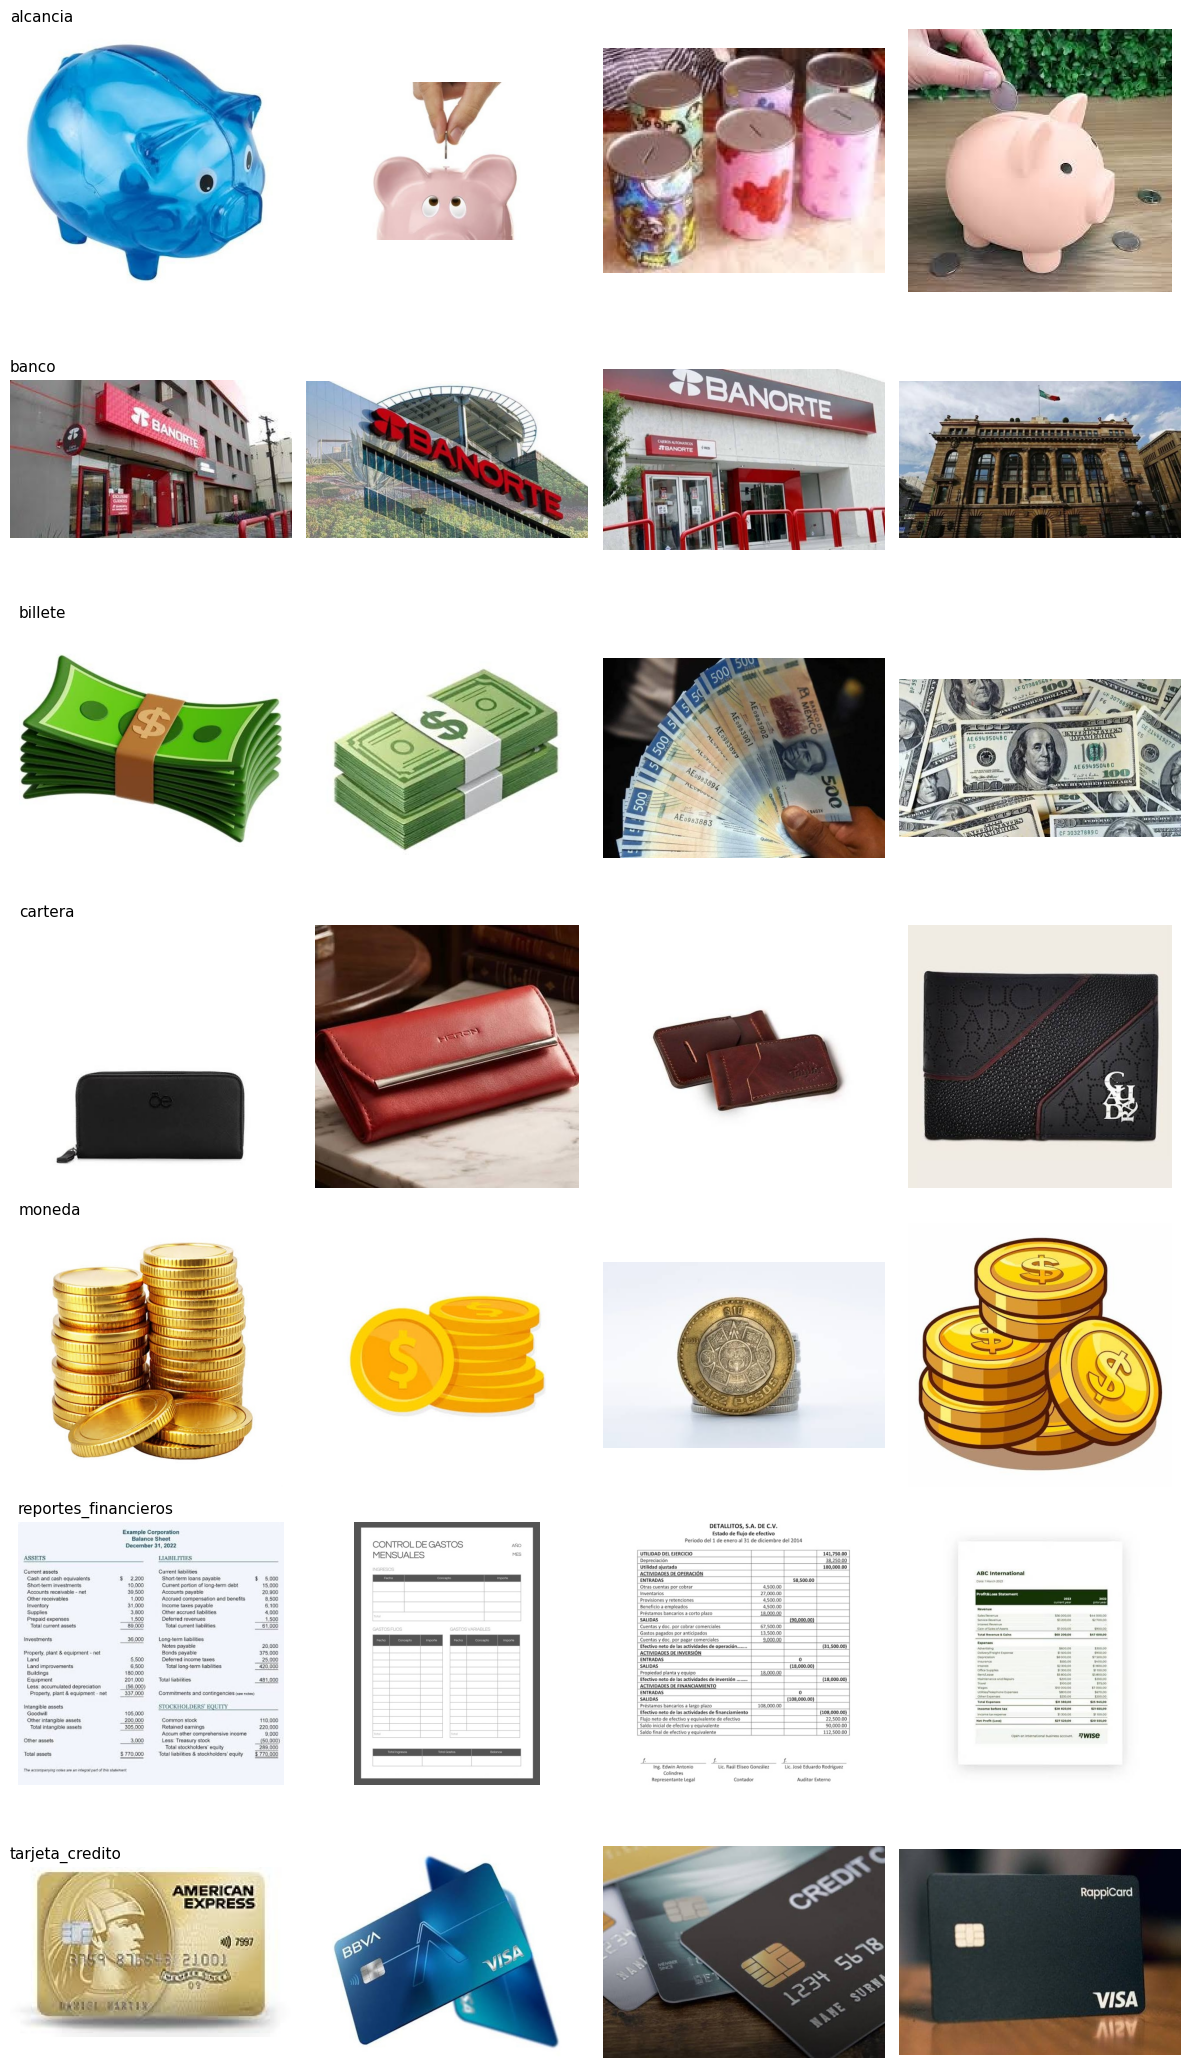

In [27]:
import matplotlib.pyplot as plt
import random

random.seed(42)

fig, ejes = plt.subplots(len(clases_img), 4, figsize=(12, 3 * len(clases_img)))

for fila, clase in enumerate(clases_img):
    archivos = list((RUTA_SPLIT / "train" / clase).glob("*.jpg"))
    for col, archivo in enumerate(random.sample(archivos, min(4, len(archivos)))):
        ejes[fila, col].imshow(Image.open(archivo))
        ejes[fila, col].axis("off")
        if col == 0:
            ejes[fila, col].set_title(clase, loc="left", fontsize=11)

plt.tight_layout()
plt.show()

In [28]:
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

print("TensorFlow:", tf.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU disponible: []


In [29]:
IMG_SIZE = (224, 224)
BATCH = 16

train_ds = keras.utils.image_dataset_from_directory(
    str(RUTA_SPLIT / "train"), image_size=IMG_SIZE, batch_size=BATCH,
    label_mode="int", shuffle=True, seed=42)

val_ds = keras.utils.image_dataset_from_directory(
    str(RUTA_SPLIT / "val"), image_size=IMG_SIZE, batch_size=BATCH,
    label_mode="int", shuffle=False)

test_ds = keras.utils.image_dataset_from_directory(
    str(RUTA_SPLIT / "test"), image_size=IMG_SIZE, batch_size=BATCH,
    label_mode="int", shuffle=False)

class_names = train_ds.class_names
test_paths = test_ds.file_paths
print("Clases:", class_names)

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 92 files belonging to 7 classes.
Found 31 files belonging to 7 classes.
Found 36 files belonging to 7 classes.
Clases: ['alcancia', 'banco', 'billete', 'cartera', 'moneda', 'reportes_financieros', 'tarjeta_credito']


In [30]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.15),
], name="aumentacion")

base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(224, 224, 3))
base_model.trainable = False
inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumentacion (Sequential)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,058,538 (15.48 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [31]:
callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=5, restore_best_weights=True)]

history = model.fit(
    train_ds, validation_data=val_ds, epochs=30, callbacks=callbacks)

Epoch 1/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 26s 2s/step - accuracy: 0.2065 - loss: 1.9529 - val_accuracy: 0.3548 - val_loss: 1.6682
Epoch 2/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.5435 - loss: 1.5287 - val_accuracy: 0.5484 - val_loss: 1.3608
Epoch 3/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.7935 - loss: 1.0507 - val_accuracy: 0.7742 - val_loss: 1.1143
Epoch 4/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.7609 - loss: 0.9446 - val_accuracy: 0.8387 - val_loss: 0.9180
Epoch 5/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 12s 2s/step - accuracy: 0.8913 - loss: 0.6922 - val_accuracy: 0.9032 - val_loss: 0.7670
Epoch 6/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 10s 2s/step - accuracy: 0.9022 - loss: 0.5951 - val_accuracy: 0.9032 - val_loss: 0.6569
Epoch 7/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - accuracy: 0.9239 - loss: 0.4689 - val_accuracy: 0.9032 - val_loss: 0.5712
Epoch 8/30
6/6 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.9565 - loss: 0.3937 - val_accuracy: 0.9032 - val_loss: 0.5064
Epoch 9/30

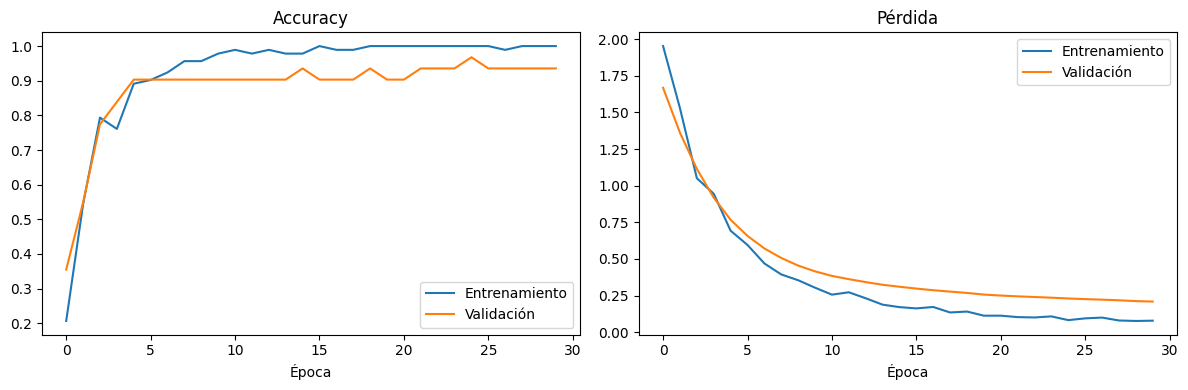

In [32]:
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

ejes[0].plot(history.history["accuracy"], label="Entrenamiento")
ejes[0].plot(history.history["val_accuracy"], label="Validación")
ejes[0].set_title("Accuracy"); ejes[0].set_xlabel("Época"); ejes[0].legend()

ejes[1].plot(history.history["loss"], label="Entrenamiento")
ejes[1].plot(history.history["val_loss"], label="Validación")
ejes[1].set_title("Pérdida"); ejes[1].set_xlabel("Época"); ejes[1].legend()

plt.tight_layout()
plt.show()

3/3 ━━━━━━━━━━━━━━━━━━━━ 7s 2s/step
Accuracy:          0.9167
Precision (macro): 0.9238
Recall (macro):    0.9190
F1-score (macro):  0.9188

                      precision    recall  f1-score   support

            alcancia       1.00      0.80      0.89         5
               banco       1.00      1.00      1.00         5
             billete       0.80      0.80      0.80         5
             cartera       0.83      1.00      0.91         5
              moneda       1.00      1.00      1.00         5
reportes_financieros       1.00      1.00      1.00         5
     tarjeta_credito       0.83      0.83      0.83         6

            accuracy                           0.92        36
           macro avg       0.92      0.92      0.92        36
        weighted avg       0.92      0.92      0.92        36



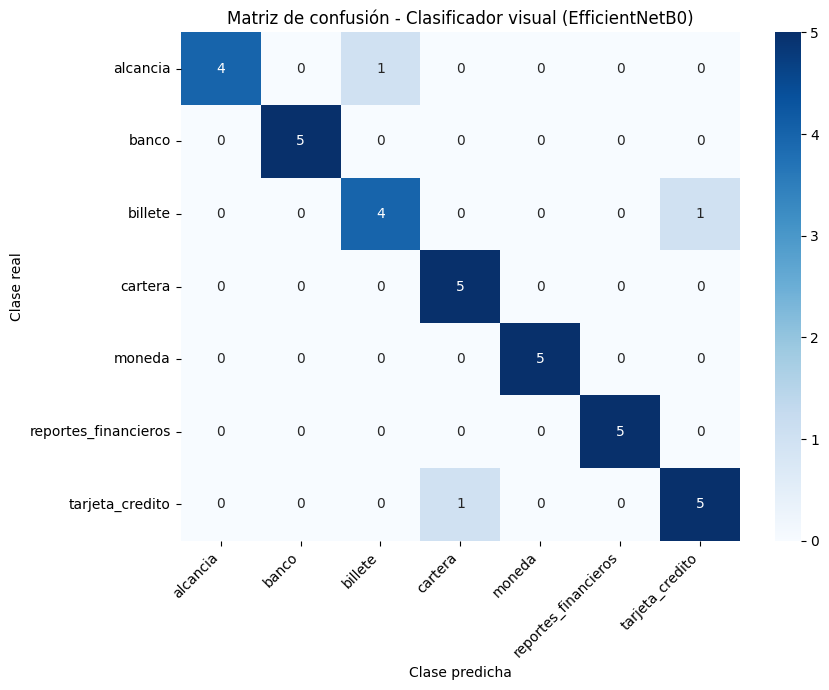

In [33]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
import seaborn as sns

y_true_img = np.concatenate([y.numpy() for _, y in test_ds])
probs = model.predict(test_ds)
y_pred_img = probs.argmax(axis=1)

print(f"Accuracy:          {accuracy_score(y_true_img, y_pred_img):.4f}")
print(f"Precision (macro): {precision_score(y_true_img, y_pred_img, average='macro', zero_division=0):.4f}")
print(f"Recall (macro):    {recall_score(y_true_img, y_pred_img, average='macro', zero_division=0):.4f}")
print(f"F1-score (macro):  {f1_score(y_true_img, y_pred_img, average='macro', zero_division=0):.4f}")
print()
print(classification_report(y_true_img, y_pred_img,
                            target_names=class_names, zero_division=0))

matriz_img = confusion_matrix(y_true_img, y_pred_img)

plt.figure(figsize=(9, 7))
sns.heatmap(matriz_img, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Matriz de confusión - Clasificador visual (EfficientNetB0)")
plt.xlabel("Clase predicha")
plt.ylabel("Clase real")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [34]:
RESPUESTAS_TEXTO = {
    "saludo": ("¡Hola! Soy un asistente de educación financiera básica. Puedo explicarte "
               "temas como ahorro, inflación, tarjetas de crédito, CETES, Afore, fondo de "
               "emergencia, presupuesto y cómo evitar fraudes. También puedes escribir "
               "'imagen' para que analice una foto. ¿Qué te gustaría saber?"),
    "despedida": "¡Con gusto! Recuerda que esto es información general. ¡Hasta pronto!",
    "ayuda": ("Puedo hablarte de: ahorro, fondo de emergencia, presupuesto, inflación, "
              "tarjeta de crédito, CAT, CETES, Afore, deudas y fraudes. También puedo "
              "analizar una imagen: escribe 'imagen' y súbela."),
    "ahorro": ("Ahorrar es separar una parte de tus ingresos antes de gastarlos. Un método "
               "común es la regla 50/30/20: 50% necesidades, 30% gustos y 20% ahorro o pago "
               "de deudas. Lo importante es empezar con una cantidad que sí puedas mantener."),
    "fondo_emergencia": ("El fondo de emergencia es dinero reservado para imprevistos (pérdida de "
                         "empleo, gastos médicos, reparaciones). Se suele recomendar juntar entre 3 y "
                         "6 meses de tus gastos básicos y mantenerlo en un instrumento de fácil acceso."),
    "presupuesto": ("Un presupuesto es un plan de cuánto ganas y en qué lo gastas. Pasos básicos: "
                    "1) anota tus ingresos, 2) registra gastos fijos y variables, 3) define un "
                    "monto de ahorro, 4) revisa cada mes y ajusta."),
    "inflacion": ("La inflación es el aumento generalizado y sostenido de los precios, lo que "
                  "reduce el poder adquisitivo de tu dinero. En México se mide con el INPC y "
                  "Banxico tiene como objetivo mantenerla baja y estable."),
    "tarjeta_credito": ("Con la tarjeta de crédito usas dinero prestado por el banco. Si pagas el "
                        "total antes de la fecha límite normalmente no pagas intereses; si pagas solo "
                        "el mínimo, los intereses pueden hacer crecer mucho la deuda."),
    "cat": ("El CAT (Costo Anual Total) es un indicador que incluye la tasa de interés, "
            "comisiones y otros costos de un crédito. Sirve para comparar créditos: a "
            "menor CAT, menor costo total."),
    "cetes": ("Los CETES son títulos de deuda emitidos por el Gobierno de México. Al "
              "comprarlos le prestas dinero al gobierno y recibes un rendimiento al "
              "vencimiento. Se pueden adquirir en la plataforma oficial CETES Directo."),
    "afore": ("La Afore administra tu cuenta individual de ahorro para el retiro. Puedes "
              "consultar tu saldo y hacer aportaciones voluntarias; la CONSAR es la "
              "autoridad que regula las Afores."),
    "deudas": ("Para salir de deudas: lista todas con su tasa de interés, evita adquirir "
               "nuevas, y paga primero la de mayor tasa (método avalancha) o la más pequeña "
               "(método bola de nieve). Si no puedes pagar, consulta a tu institución sobre "
               "opciones de reestructura y a la Condusef."),
    "fraude": ("Para evitar fraudes: nunca compartas NIP, contraseñas o códigos por "
               "mensaje o llamada, verifica que los enlaces sean oficiales y desconfía de "
               "ofertas con rendimientos 'garantizados' muy altos. Ante un cargo "
               "desconocido, contacta de inmediato a tu banco."),}

RESPUESTAS_IMAGEN = {
    "alcancia": ("una alcancía. Es una forma sencilla de ahorrar: separar una cantidad fija cada "
                 "semana o mes ayuda a crear el hábito. Pregúntame sobre ahorro o fondo de emergencia."),
    "banco": ("un banco o sucursal bancaria. Ahí puedes abrir cuentas o resolver dudas, pero "
              "nunca compartas tu NIP o contraseñas. Pregúntame cómo evitar fraudes."),
    "billete": ("un billete. Con el efectivo conviene llevar un control de gastos y tener en "
                "cuenta que la inflación reduce lo que puedes comprar con él. Pregúntame sobre "
                "presupuesto o inflación."),
    "cartera": ("una cartera. Es donde solemos llevar efectivo y tarjetas, así que conviene "
                "cuidarla y no guardar NIP ni contraseñas dentro. Pregúntame sobre fraudes."),
    "moneda": ("una moneda. Las monedas también cuentan: guardar el cambio es una buena manera de "
               "empezar a ahorrar. Pregúntame sobre ahorro."),
    "reportes_financieros": ("un reporte o documento financiero, como un balance o una gráfica. "
                             "Sirve para entender ingresos, gastos y resultados. Pregúntame sobre "
                             "presupuesto o inversión."),
    "tarjeta_credito": ("una tarjeta bancaria. Si es de crédito, revisa la fecha de corte, la "
                        "fecha límite de pago y el CAT, y evita pagar solo el mínimo. Pregúntame "
                        "sobre tarjetas de crédito o el CAT."),}

In [35]:
def responder_texto(texto):
    intencion = predecir_intencion(texto)
    return intencion, RESPUESTAS_TEXTO[intencion]


def clasificar_imagen(ruta):
    img = keras.utils.load_img(ruta, target_size=IMG_SIZE)
    arr = np.expand_dims(keras.utils.img_to_array(img), axis=0)
    probs = model.predict(arr, verbose=0)[0]
    i = int(np.argmax(probs))
    return class_names[i], float(probs[i])


def responder_imagen(ruta, umbral=0.60):
    clase, confianza = clasificar_imagen(ruta)
    if confianza < umbral:
        return (f"No estoy seguro de qué muestra la imagen (mi mejor opción fue '{clase}' "
                f"con {confianza:.0%} de confianza). Prueba con otra foto más clara.")
    return (f"La imagen parece ser {RESPUESTAS_IMAGEN[clase]} "
            f"(confianza del modelo: {confianza:.0%}).")

In [39]:
def responder_multimodal(texto, ruta_imagen, umbral=0.60):


    intencion = predecir_intencion(texto)


    clase, confianza = clasificar_imagen(ruta_imagen)


    if confianza < umbral:
        return (
            f"No estoy suficientemente seguro de lo que aparece en la imagen "
            f"(confianza: {confianza:.0%}). Prueba con una imagen más clara.")


    respuesta_texto = RESPUESTAS_TEXTO[intencion]


    respuesta_imagen = RESPUESTAS_IMAGEN[clase]


    respuesta_final = (
        f"La imagen parece ser {respuesta_imagen} "
        f"(confianza: {confianza:.0%}).\n\n"
        f"{respuesta_texto}")

    return respuesta_final

In [40]:
PALABRAS_IMAGEN = ["imagen", "foto", "fotografia", "analiza"]

def chatear_multimodal():
    print("Asistente financiero multimodal (escribe 'salir' para terminar)")
    print("Puedes hacer una pregunta de texto o incluir una imagen.\n")

    while True:
        entrada = input("Tú: ").strip()

        if entrada.lower() in {"salir", "exit"}:
            print("Bot: ¡Hasta pronto!")
            break


        if any(p in quitar_acentos(entrada.lower()) for p in PALABRAS_IMAGEN):

            print("Bot: Claro, sube la imagen.")
            subidos = files.upload()

            if not subidos:
                print("Bot: No recibí ninguna imagen.\n")
                continue

            ruta = list(subidos.keys())[0]


            respuesta = responder_multimodal(entrada, ruta)

            print("Bot:", respuesta, "\n")

        else:
            _, respuesta = responder_texto(entrada)

            print("Bot:", respuesta, "\n")


In [ ]:
chatear_multimodal()

Asistente financiero multimodal (escribe 'salir' para terminar)
Puedes hacer una pregunta de texto o incluir una imagen.

Tú: buenas noches
Bot: ¡Hola! Soy un asistente de educación financiera básica. Puedo explicarte temas como ahorro, inflación, tarjetas de crédito, CETES, Afore, fondo de emergencia, presupuesto y cómo evitar fraudes. También puedes escribir 'imagen' para que analice una foto. ¿Qué te gustaría saber? 

Tú: explicame sobre los cetes
Bot: Los CETES son títulos de deuda emitidos por el Gobierno de México. Al comprarlos le prestas dinero al gobierno y recibes un rendimiento al vencimiento. Se pueden adquirir en la plataforma oficial CETES Directo. 

Tú: cual es la funcion del afore?
Bot: La Afore administra tu cuenta individual de ahorro para el retiro. Puedes consultar tu saldo y hacer aportaciones voluntarias; la CONSAR es la autoridad que regula las Afores. 

Tú: para que me sirve un fondo de emergencia?
Bot: El fondo de emergencia es dinero reservado para imprevistos

Saving prueba3.jpg to prueba3.jpg
Bot: No estoy suficientemente seguro de lo que aparece en la imagen (confianza: 45%). Prueba con una imagen más clara. 

Tú: imagen
Bot: Claro, sube la imagen.


Saving prueba2.jpg to prueba2 (1).jpg
Bot: La imagen parece ser una moneda. Las monedas también cuentan: guardar el cambio es una buena manera de empezar a ahorrar. Pregúntame sobre ahorro. (confianza: 95%).

¡Con gusto! Recuerda que esto es información general. ¡Hasta pronto! 

Tú: analiza esta imagen y dime como me puede ayudar a ahorra
Bot: Claro, sube la imagen.


Saving prueba 5.png to prueba 5 (1).png
Bot: La imagen parece ser una alcancía. Es una forma sencilla de ahorrar: separar una cantidad fija cada semana o mes ayuda a crear el hábito. Pregúntame sobre ahorro o fondo de emergencia. (confianza: 88%).

Puedo hablarte de: ahorro, fondo de emergencia, presupuesto, inflación, tarjeta de crédito, CAT, CETES, Afore, deudas y fraudes. También puedo analizar una imagen: escribe 'imagen' y súbela. 

Tú: explicame esta imagen
Bot: Claro, sube la imagen.


Saving Prueba 1.webp to Prueba 1 (1).webp
Bot: La imagen parece ser un billete. Con el efectivo conviene llevar un control de gastos y tener en cuenta que la inflación reduce lo que puedes comprar con él. Pregúntame sobre presupuesto o inflación. (confianza: 86%).

Puedo hablarte de: ahorro, fondo de emergencia, presupuesto, inflación, tarjeta de crédito, CAT, CETES, Afore, deudas y fraudes. También puedo analizar una imagen: escribe 'imagen' y súbela. 

Tú: como termino el marcador del partido?
Bot: ¡Con gusto! Recuerda que esto es información general. ¡Hasta pronto! 

Tú: como esta el clima?
Bot: ¡Con gusto! Recuerda que esto es información general. ¡Hasta pronto! 

